# [Lab Session 4](deconvolution.ipynb)

In [16]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

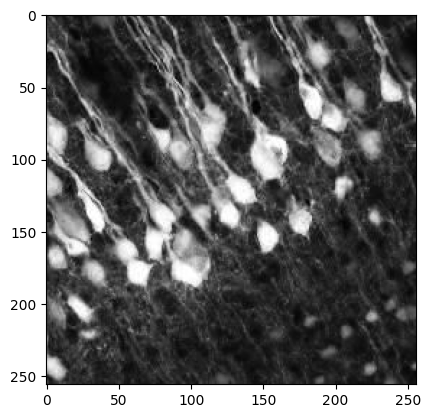

In [17]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [18]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

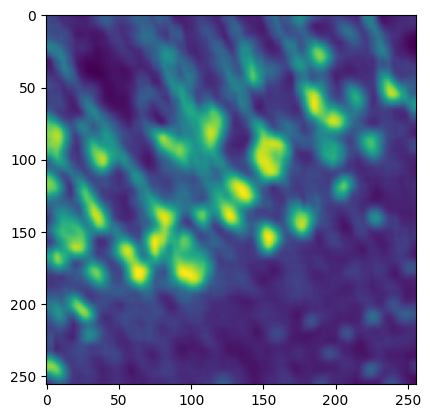

In [ ]:
cells = conv(img, psf, mode='same',  boundary='symm') #image blurred wih psf
plt.imshow(cells)

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

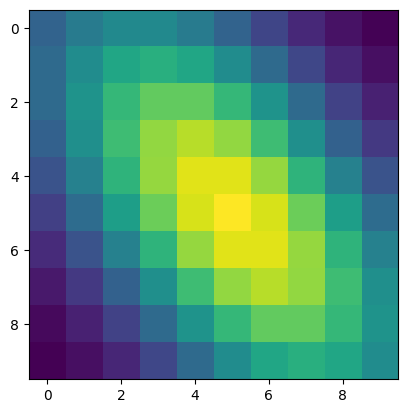

In [20]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size))

Apply the second psf to the image:

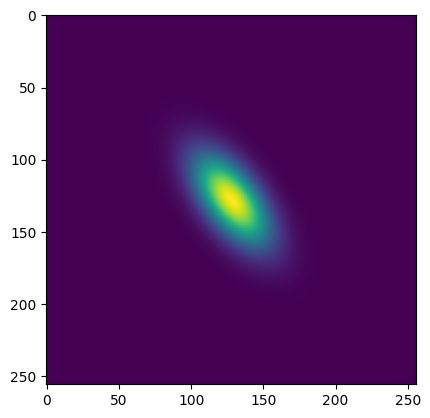

In [21]:
psf_applied = create_psf(cells.shape[0])
plt.imshow(psf_applied)

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [33]:
def richardson_lucy_deconvolution(image, psf, n_iterations): #image= input blurred image; psf= point spread function; n_iterations= number of iterations
    img_deconv = np.full(image.shape, 0.5, dtype=float)
    psf_flipped =np.flip(psf)
   
    for t in range (n_iterations):
        conv_result =conv(img_deconv, psf, mode ='same', boundary='symm')
        ratio = image /conv_result
        correction = conv(ratio, psf_flipped, mode ='same', boundary='symm')
        img_deconv *= correction
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [39]:
deconv_img = richardson_lucy_deconvolution(cells, psf, 100)


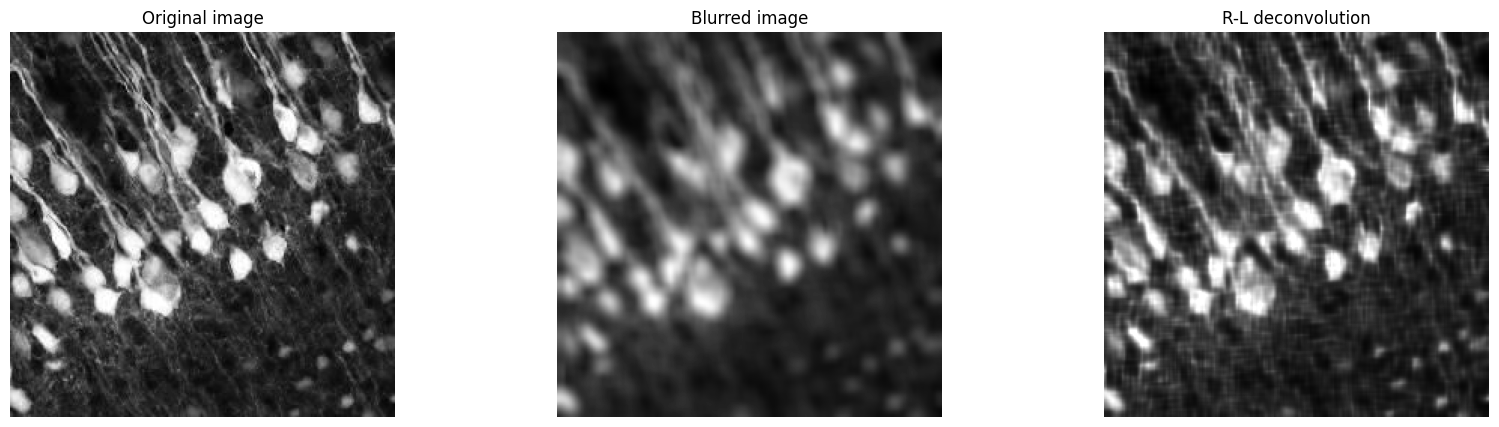

In [38]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(cells, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [40]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

In [49]:
img_with_noise = cells + noise

In [50]:
img_with_noise = np.clip(img_with_noise, 0,1) #image clipping
noisy_image_deconv = richardson_lucy_deconvolution(img_with_noise, psf, 50)

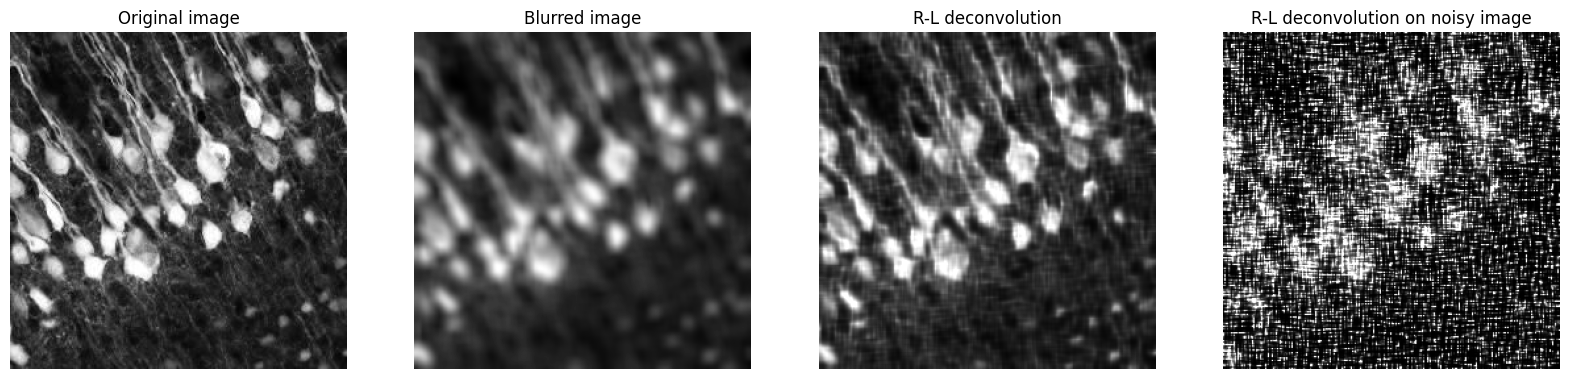

In [51]:
plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(cells, 'gray')
plt.title('Blurred image')
plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.subplot(1,4,4)
plt.axis('off')
plt.imshow(noisy_image_deconv, 'gray')
plt.title('R-L deconvolution on noisy image')
plt.show()

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

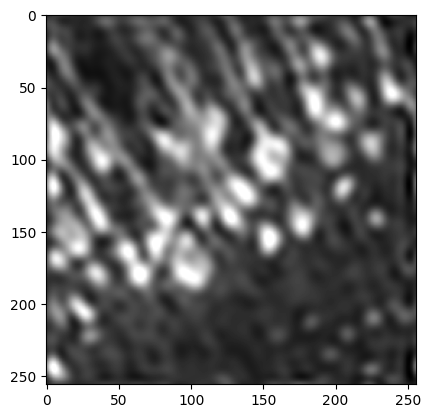

In [61]:
cells_wiener =wiener(cells, psf, balance =2, clip= True)
plt.imshow(cells_wiener, 'grey')

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

In [64]:
psf_size_new = 5
psf_new = np.ones((psf_size_new, psf_size_new)) / psf_size_new ** 2
deconv_img_new = richardson_lucy_deconvolution(cells, psf, 100)


**[Task 8.]()** Use a wrong PSF to restore the image